# Протокол виконання лабораторної роботи №5
**Тема:** Кластеризація
**Мета:** Ознайомитись з основами машинного навчання без учителя, реалізувати метод К-середніх (K-Means) на NumPy та дослідити інші алгоритми кластеризації з бібліотеки scikit-learn.

## 1. Підготовка даних та розвідувальний аналіз
Завантажимо дані, перевіримо їх на наявність пропусків та проведемо стандартизацію. У навчанні без учителя ми не використовуємо цільову змінну `y`, алгоритм сам шукає приховані структури.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

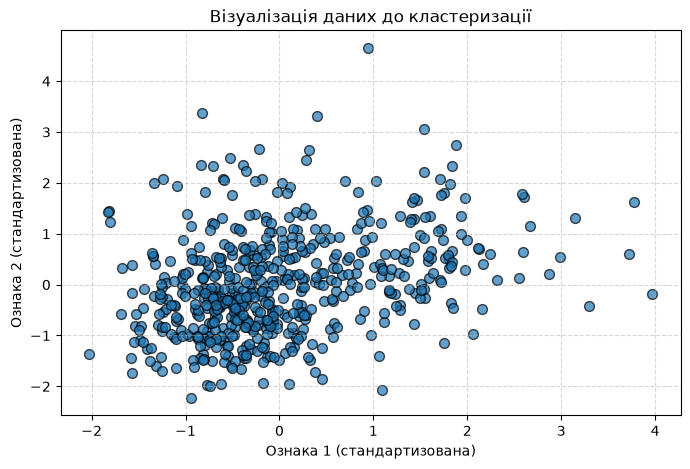

In [4]:
# Завантажуємо ваш датасет
df = pd.read_csv('data/data.csv')

# Відбираємо ознаки для кластеризації (2 числові колонки)
# Беремо їх відразу, ігноруючи решту датафрейму
X_df = df.iloc[:, 2:4]

# Якщо в цих двох колонках дійсно є пропуски - видаляємо рядки лише для них
X_df = X_df.dropna()
X = X_df.values 

# Стандартизація даних 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Візуалізація підготовлених даних
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=50, alpha=0.7, edgecolors='k')
plt.title('Візуалізація даних до кластеризації')
plt.xlabel('Ознака 1 (стандартизована)')
plt.ylabel('Ознака 2 (стандартизована)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 2. Реалізація алгоритму KMeans на NumPy
Згідно із завданням, реалізуємо метод K-Середніх без використання готових рішень зі sklearn для розуміння його внутрішньої логіки.

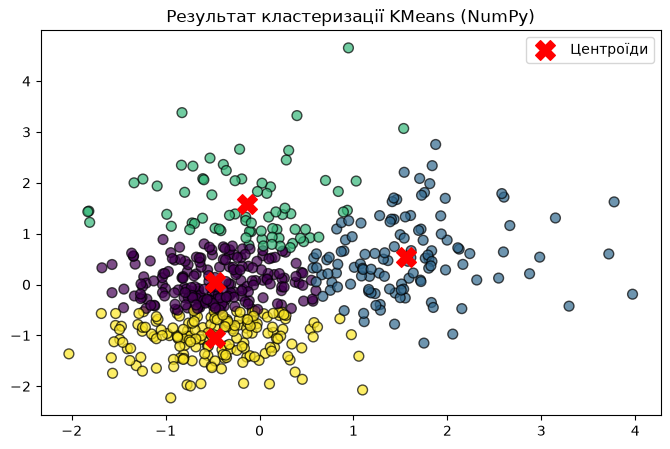

In [5]:
class KMeansNumPy:
    def __init__(self, n_clusters=3, max_iters=100, tol=1e-4):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.tol = tol
        self.centroids = None
        self.inertia_ = 0 # Сума квадратів відстаней до центроїдів (WCSS)

    def fit(self, X):
        # 1. Ініціалізація центроїдів випадковими точками з датасету
        np.random.seed(42)
        random_idx = np.random.permutation(X.shape[0])
        self.centroids = X[random_idx[:self.n_clusters]]

        for i in range(self.max_iters):
            # 2. Призначення кластерів (обчислення евклідової відстані)
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            labels = np.argmin(distances, axis=1)

            # 3. Оновлення центроїдів (обчислення середнього значення)
            new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(self.n_clusters)])

            # Перевірка на збіжність (чи змінилися центроїди)
            if np.all(np.abs(new_centroids - self.centroids) < self.tol):
                break
            self.centroids = new_centroids
            
        # Обчислення inertia (WCSS) для методу ліктя
        self.inertia_ = np.sum([np.sum((X[labels == k] - self.centroids[k])**2) for k in range(self.n_clusters)])
        return labels

# Тестування нашої реалізації
kmeans_custom = KMeansNumPy(n_clusters=4)
labels_custom = kmeans_custom.fit(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_custom, cmap='viridis', s=50, alpha=0.7, edgecolors='k')
plt.scatter(kmeans_custom.centroids[:, 0], kmeans_custom.centroids[:, 1], c='red', s=200, marker='X', label='Центроїди')
plt.title('Результат кластеризації KMeans (NumPy)')
plt.legend()
plt.show()

## 3. Вибір оптимальної кількості кластерів (Метод ліктя)
Для оцінки оптимальної кількості кластерів використаємо критерій WCSS (Within-Cluster Sum of Square) — суму квадратів відстаней від точок до центрів їхніх кластерів.

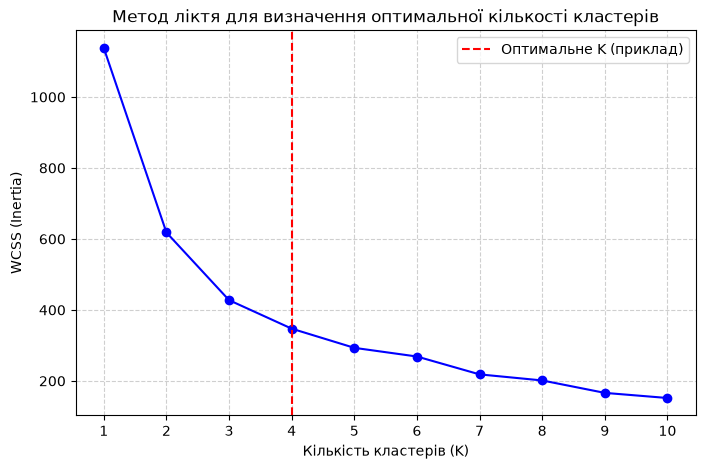

In [6]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    model = KMeansNumPy(n_clusters=k)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', linestyle='-', color='b')
plt.title('Метод ліктя для визначення оптимальної кількості кластерів')
plt.xlabel('Кількість кластерів (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.axvline(x=4, color='r', linestyle='--', label='Оптимальне K (приклад)')
plt.legend()
plt.show()

## 4. Застосування додаткових методів кластеризації зі Sklearn (на максимальний бал)
Продемонструємо роботу методів DBSCAN (кластеризація на основі щільності) та Agglomerative Clustering (ієрархічна кластеризація).

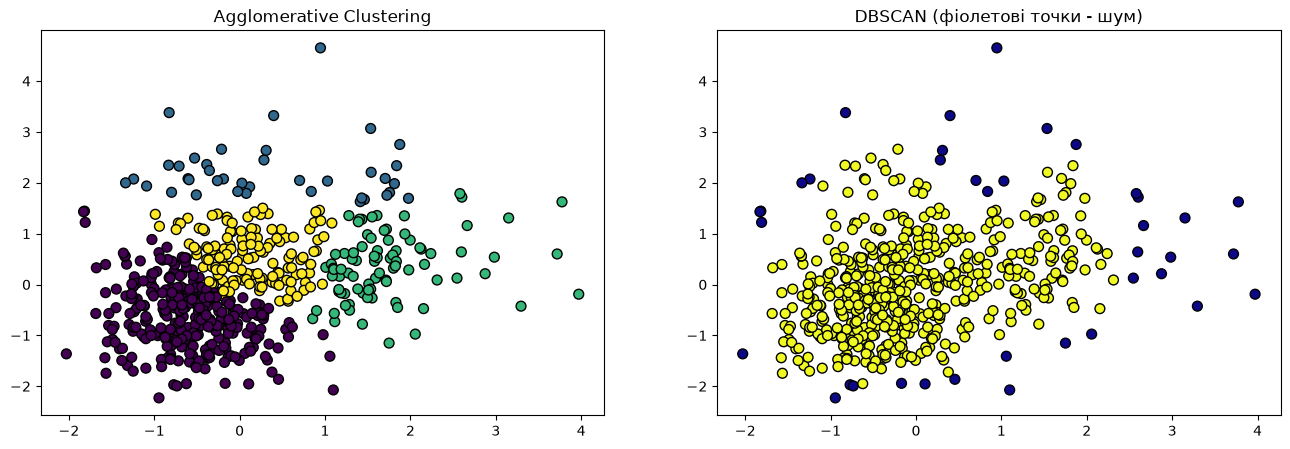

In [7]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering

# 1. Agglomerative Clustering
agg_clustering = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg_clustering.fit_predict(X_scaled)

# 2. DBSCAN (не потребує задання кількості кластерів наперед)
dbscan = DBSCAN(eps=0.35, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Візуалізація порівняння
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=agg_labels, cmap='viridis', s=50, edgecolors='k')
axes[0].set_title('Agglomerative Clustering')

# Від'ємні мітки в DBSCAN означають шум (викиди)
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=dbscan_labels, cmap='plasma', s=50, edgecolors='k')
axes[1].set_title('DBSCAN (фіолетові точки - шум)')

plt.show()

## 5. Аналіз результатів та відповіді на контрольні питання

### Аналіз результатів
1. **Вибір оптимальної кількості кластерів:** На графіку методу ліктя (Elbow method) не спостерігається чітко вираженого "згину" (перелому). Значення WCSS спадає плавно, без різких стрибків. Це свідчить про те, що у вибраних двох ознаках немає яскраво виражених, природно відокремлених кластерів — дані виглядають як одне суцільне хмара точок. Вибір кількості кластерів (наприклад, K=4) у цьому випадку є умовним і задається користувачем примусово.
2. **Оцінка результатів при різній кількості:** Оскільки природних ізольованих згустків немає, алгоритми K-Means та Agglomerative Clustering просто геометрично "розрізали" єдиний масив даних на задану кількість частин. Межі між цими кластерами є штучними, алгоритм просто відносив точки до найближчих математичних центрів, ігноруючи відсутність розривів у просторі.
3. **Порівняння алгоритмів:** Найбільш логічною для такої структури даних виявилася робота алгоритму `DBSCAN`. Оскільки він шукає кластери на основі щільності, він коректно визначив усю центральну щільну масу даних як один великий суцільний кластер (жовті точки), а розріджені точки на периферії відніс до шуму або аномалій (темні точки). Це повністю підтверджує відсутність кількох окремих кластерів у цих вимірах.

### Відповіді на контрольні питання
1. **Як працюють методи машинного навчання без учителя?**
   Методи навчання без учителя працюють із даними, які не мають заздалегідь відомих міток (відповідей) або цільової змінної. Їхня мета — самостійно знайти приховані структури, закономірності, правила або групи (кластери) у сирих даних на основі їхніх характеристик (наприклад, використовуючи метрики відстані або щільності).
2. **Критерій оптимальної кількості кластерів?**
   Найпоширенішим критерієм є **Метод ліктя (Elbow method)**, який аналізує метрику WCSS (сума квадратів відстаней від кожної точки до центру її кластера). Оптимальною вважається така кількість кластерів, при якій додавання нового кластера вже не дає суттєвого зменшення WCSS (на графіку утворюється "згин ліктя"). Також часто використовується метрика **Силуету (Silhouette score)**, яка оцінює, наскільки об'єкт схожий на свій кластер порівняно з іншими кластерами (значення ближче до 1 свідчить про високу якість кластеризації).